# Decision Tree-model voor stroke prediction

Dit notebook bevat het **Decision Tree-onderdeel** voor de opdracht *Voorspel herseninfarct*.

Doel:
- voorspellen of een patiënt een herseninfarct krijgt (`stroke`);
- het Decision Tree-model uitleggen;
- hyperparameter tuning en cross-validation toepassen;
- omgaan met de imbalanced dataset;
- evalueren met F1-score en confusion matrix;
- een Kaggle-submissionbestand maken.


## 1. Imports en instellingen

In deze stap importeren we de libraries die nodig zijn voor:
- data inladen en bewerken;
- train/validatie-splitsing;
- Decision Tree-model;
- hyperparameter tuning;
- evaluatie;
- visualisaties.


In [4]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


## 2. Data inladen

We gebruiken:
- `train.csv` om het model te trainen en te valideren;
- `test.csv` om voorspellingen te maken voor Kaggle;
- `sample_submission.csv` als voorbeeld van het juiste indienformaat.

De kolom `stroke` is de target:
- `0` = geen herseninfarct;
- `1` = wel herseninfarct.


In [5]:
train_path = "../data/train.csv"
test_path = "../data/test.csv"
sample_submission_path = "../data/sample_submission.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
sample_submission_df = pd.read_csv(sample_submission_path)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
display(train_df.head())
display(sample_submission_df.head())


Train shape: (33550, 22)
Test shape: (8388, 21)


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,...,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,...,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,...,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,...,False,False,True,False,True,False,True,False,False,0


,id,stroke
0,32840,1
1,45158,0
2,56105,1
3,3112,0
4,35224,1


## 3. Korte datacontrole

De dataset is al gedeeltelijk voorbewerkt. Categorieën zoals `gender`, `work_type`, `Residence_type` en `smoking_status` staan al als dummyvariabelen in de dataset.

Voor een Decision Tree is standaardisatie niet nodig. Een beslisboom splitst namelijk op voorwaarden zoals:

$$
\text{age} \leq 67.5
$$

Daarom maakt de schaal van de variabelen minder uit dan bij bijvoorbeeld SVM of Logistic Regression.


In [6]:
display(train_df.info())

missing_values = train_df.isna().sum().sort_values(ascending=False)
display(missing_values[missing_values > 0])

class_distribution = train_df["stroke"].value_counts()
class_distribution_percent = train_df["stroke"].value_counts(normalize=True) * 100

print("Verdeling target:")
display(pd.DataFrame({
    "aantal": class_distribution,
    "percentage": class_distribution_percent.round(2),
}))


<class 'pandas.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  bool   
 7   gender_Male                     33550 non-null  bool   
 8   gender_Other                    33550 non-null  bool   
 9   ever_married_No                 33550 non-null  bool   
 10  ever_married_Yes                33550 non-null  bool   
 11  work_type_Govt_job              33550 non-null  bool   
 12  work_type_Never_worked          33550 non-n

None

Series([], dtype: int64)

Verdeling target:


,aantal,percentage
stroke,,
0,33033,98.46
1,517,1.54


## 4. Features en target maken

De kolom `id` gebruiken we niet als feature, omdat dit alleen een identificatienummer is.  
De target is `stroke`.


In [7]:
X = train_df.drop(columns=["id", "stroke"])
y = train_df["stroke"].astype(int)

X_test = test_df.drop(columns=["id"])
test_ids = test_df["id"]

print("Aantal features:", X.shape[1])
print("Features:")
print(list(X.columns))


Aantal features: 20
Features:
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Female', 'gender_Male', 'gender_Other', 'ever_married_No', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Rural', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']


## 5. Train- en validatieset

We splitsen de data in:
- trainingsdata: om het model te trainen;
- validatiedata: om het model te testen op data die het nog niet heeft gezien.

We gebruiken `stratify=y`, zodat de verhouding tussen `stroke = 0` en `stroke = 1` ongeveer gelijk blijft in beide sets. Dit is belangrijk omdat de dataset sterk imbalanced is.


In [8]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Train targetverdeling:")
print(y_train.value_counts(normalize=True).round(4))

print("\nValidatie targetverdeling:")
print(y_valid.value_counts(normalize=True).round(4))


Train targetverdeling:
stroke
0    0.9846
1    0.0154
Name: proportion, dtype: float64

Validatie targetverdeling:
stroke
0    0.9846
1    0.0154
Name: proportion, dtype: float64


## 6. Uitleg Decision Tree

Een Decision Tree is een model dat voorspellingen maakt met een reeks beslisregels.  
Het model stelt steeds vragen over de data, bijvoorbeeld:

$$
\text{age} \leq 55
$$

of

$$
\text{avg\_glucose\_level} \leq 120
$$

Elke splitsing verdeelt de dataset in kleinere groepen. Het doel is dat de groepen steeds “zuiverder” worden: dus zoveel mogelijk patiënten met dezelfde klasse bij elkaar.

### Splitsingscriteria

Een beslisboom kan verschillende criteria gebruiken om te bepalen welke splitsing goed is.

**Gini impurity**

$$
Gini = 1 - \sum_{i=1}^{k} p_i^2
$$

Hierbij is $$p_i$$ het aandeel van klasse $$i$$ in een node. Hoe lager de Gini impurity, hoe zuiverder de node.

**Entropy**

$$
Entropy = -\sum_{i=1}^{k} p_i \log_2(p_i)
$$

Ook hier geldt: hoe lager de entropy, hoe zuiverder de node.

### Pruning, underfitting en overfitting

Een Decision Tree kan snel overfitten. Dat betekent dat het model de trainingsdata te goed uit het hoofd leert en slechter presteert op nieuwe data.

Pruning helpt om dit te voorkomen. Voorbeelden van pruning/hyperparameters zijn:
- `max_depth`: maximale diepte van de boom;
- `min_samples_leaf`: minimaal aantal observaties in een eindblad;
- `min_samples_split`: minimaal aantal observaties nodig om nog te mogen splitten;
- `ccp_alpha`: cost-complexity pruning, waarbij een complexere boom sterker wordt afgestraft.

Te veel pruning kan leiden tot underfitting: het model is dan te simpel. Te weinig pruning kan leiden tot overfitting: het model is dan te complex.


## 7. Baseline Decision Tree

Eerst trainen we een eenvoudige Decision Tree zonder tuning.  
Omdat de dataset imbalanced is, gebruiken we `class_weight="balanced"`. Daarmee krijgt de minder voorkomende klasse `stroke = 1` meer gewicht tijdens het trainen.


In [9]:
baseline_tree = DecisionTreeClassifier(
    random_state=RANDOM_STATE,
    class_weight="balanced",
)

baseline_tree.fit(X_train, y_train)

baseline_pred = baseline_tree.predict(X_valid)

baseline_scores = {
    "model": "Baseline Decision Tree",
    "f1": f1_score(y_valid, baseline_pred, zero_division=0),
    "precision": precision_score(y_valid, baseline_pred, zero_division=0),
    "recall": recall_score(y_valid, baseline_pred, zero_division=0),
    "accuracy": accuracy_score(y_valid, baseline_pred),
}

display(pd.DataFrame([baseline_scores]))


,model,f1,precision,recall,accuracy
0,Baseline Decision Tree,0.05102,0.053763,0.048544,0.97228


## 8. Hyperparameter tuning met cross-validation

We zoeken betere instellingen met `GridSearchCV`.  
De gekozen metric is **F1-score**, omdat Kaggle hier ook op beoordeelt en omdat de dataset imbalanced is.

De F1-score combineert precision en recall:

$$
F1 = 2 \cdot \frac{precision \cdot recall}{precision + recall}
$$

Bij deze medische toepassing is recall belangrijk, omdat we patiënten met risico op een herseninfarct niet willen missen. Tegelijk mag precision niet volledig genegeerd worden, omdat te veel fout-positieven ook gevolgen hebben.


In [10]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 4, 5, 6, 8, 10],
    "min_samples_split": [2, 50, 100],
    "min_samples_leaf": [25, 50, 100, 200],
    "max_features": [None],
    "class_weight": ["balanced"],
    "ccp_alpha": [0.0, 0.0001, 0.001],
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)

grid_search.fit(X_train, y_train)

print("Beste gemiddelde CV F1-score:", round(grid_search.best_score_, 4))
print("Beste hyperparameters:")
display(grid_search.best_params_)


Beste gemiddelde CV F1-score: 0.0898
Beste hyperparameters:


{'ccp_alpha': 0.0,
 'class_weight': 'balanced',
 'criterion': 'gini',
 'max_depth': 6,
 'max_features': None,
 'min_samples_leaf': 200,
 'min_samples_split': 2}

## 9. Validatie van het beste model

We evalueren het beste model op de validatieset.  
Eerst gebruiken we de standaard threshold van `0.5`. Daarna zoeken we een betere threshold voor de F1-score.


In [11]:
best_tree = grid_search.best_estimator_

valid_proba = best_tree.predict_proba(X_valid)[:, 1]
valid_pred_default = (valid_proba >= 0.5).astype(int)

print("Classification report bij threshold 0.5:")
print(classification_report(y_valid, valid_pred_default, zero_division=0))


Classification report bij threshold 0.5:
              precision    recall  f1-score   support

           0       0.99      0.74      0.85      6607
           1       0.04      0.71      0.08       103

    accuracy                           0.74      6710
   macro avg       0.52      0.73      0.46      6710
weighted avg       0.98      0.74      0.84      6710



Beste threshold op validatieset:


,threshold,f1,precision,recall,accuracy,roc_auc,pr_auc,tn,fp,fn,tp
70,0.71,0.12178,0.069241,0.504854,0.888227,0.830077,0.053111,5908.0,699.0,51.0,52.0


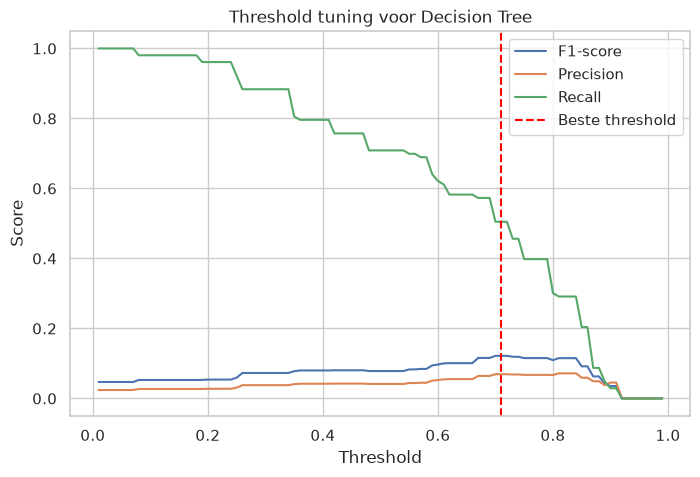

In [12]:
def evaluate_threshold(y_true, probabilities, threshold):
    """Bereken metrics voor een gekozen threshold."""
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions).ravel()

    return {
        "threshold": threshold,
        "f1": f1_score(y_true, predictions, zero_division=0),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "accuracy": accuracy_score(y_true, predictions),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "pr_auc": average_precision_score(y_true, probabilities),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    }


threshold_results = []

for threshold in np.linspace(0.01, 0.99, 99):
    threshold_results.append(
        evaluate_threshold(y_valid, valid_proba, threshold)
    )

threshold_df = pd.DataFrame(threshold_results)
best_threshold_row = threshold_df.sort_values(
    "f1",
    ascending=False,
).iloc[0]

print("Beste threshold op validatieset:")
display(best_threshold_row.to_frame().T)

plt.figure(figsize=(8, 5))
plt.plot(threshold_df["threshold"], threshold_df["f1"], label="F1-score")
plt.plot(threshold_df["threshold"], threshold_df["precision"], label="Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], label="Recall")
plt.axvline(
    best_threshold_row["threshold"],
    color="red",
    linestyle="--",
    label="Beste threshold",
)
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold tuning voor Decision Tree")
plt.legend()
plt.show()


## 10. Confusion matrix

De confusion matrix laat zien:
- true negatives: correct voorspeld als geen stroke;
- false positives: onterecht voorspeld als stroke;
- false negatives: onterecht voorspeld als geen stroke;
- true positives: correct voorspeld als stroke.

Voor deze opdracht zijn vooral false negatives belangrijk, omdat dat patiënten zijn die mogelijk risico lopen maar niet worden herkend door het model.


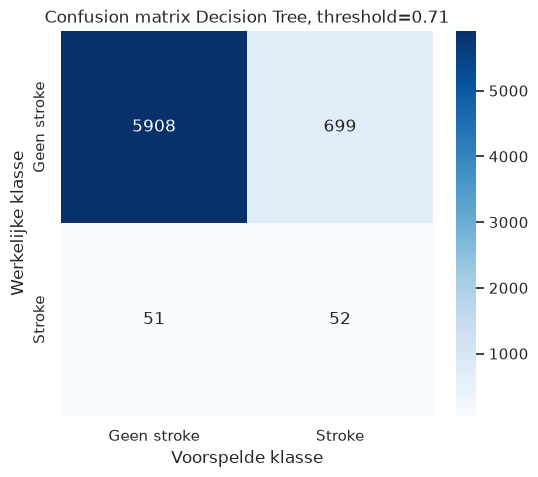

,threshold,f1,precision,recall,accuracy,roc_auc,pr_auc,tn,fp,fn,tp
0,0.71,0.12178,0.069241,0.504854,0.888227,0.830077,0.053111,5908,699,51,52


In [13]:
best_threshold = float(best_threshold_row["threshold"])
valid_pred_best = (valid_proba >= best_threshold).astype(int)

cm = confusion_matrix(y_valid, valid_pred_best)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Geen stroke", "Stroke"],
    yticklabels=["Geen stroke", "Stroke"],
)
plt.xlabel("Voorspelde klasse")
plt.ylabel("Werkelijke klasse")
plt.title(f"Confusion matrix Decision Tree, threshold={best_threshold:.2f}")
plt.show()

final_metrics = evaluate_threshold(y_valid, valid_proba, best_threshold)
display(pd.DataFrame([final_metrics]))


## 11. Feature importance

Een voordeel van een Decision Tree is dat het model relatief goed uitlegbaar is.  
Met feature importance kunnen we zien welke variabelen het model het meest gebruikt voor splitsingen.


,feature,importance
0,age,8.579936e-01
3,avg_glucose_level,5.460195e-02
4,bmi,2.644084e-02
1,hypertension,1.657314e-02
18,smoking_status_never smoked,1.497665e-02
6,gender_Male,1.153613e-02
16,Residence_type_Urban,7.760611e-03
2,heart_disease,5.904015e-03
15,Residence_type_Rural,4.213068e-03
19,smoking_status_smokes,9.063030e-15


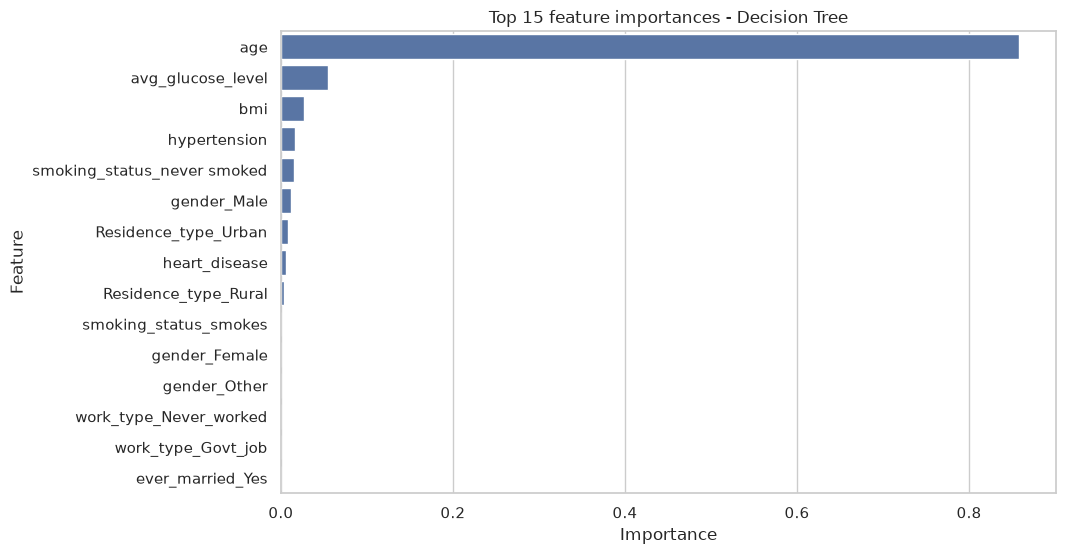

In [14]:
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": best_tree.feature_importances_,
}).sort_values("importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(15),
    x="importance",
    y="feature",
)
plt.title("Top 15 feature importances - Decision Tree")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()


## 12. Kleine visualisatie van de boom

Een volledige boom kan groot en onoverzichtelijk zijn. Daarom tonen we alleen de bovenste lagen met `max_depth=3`.


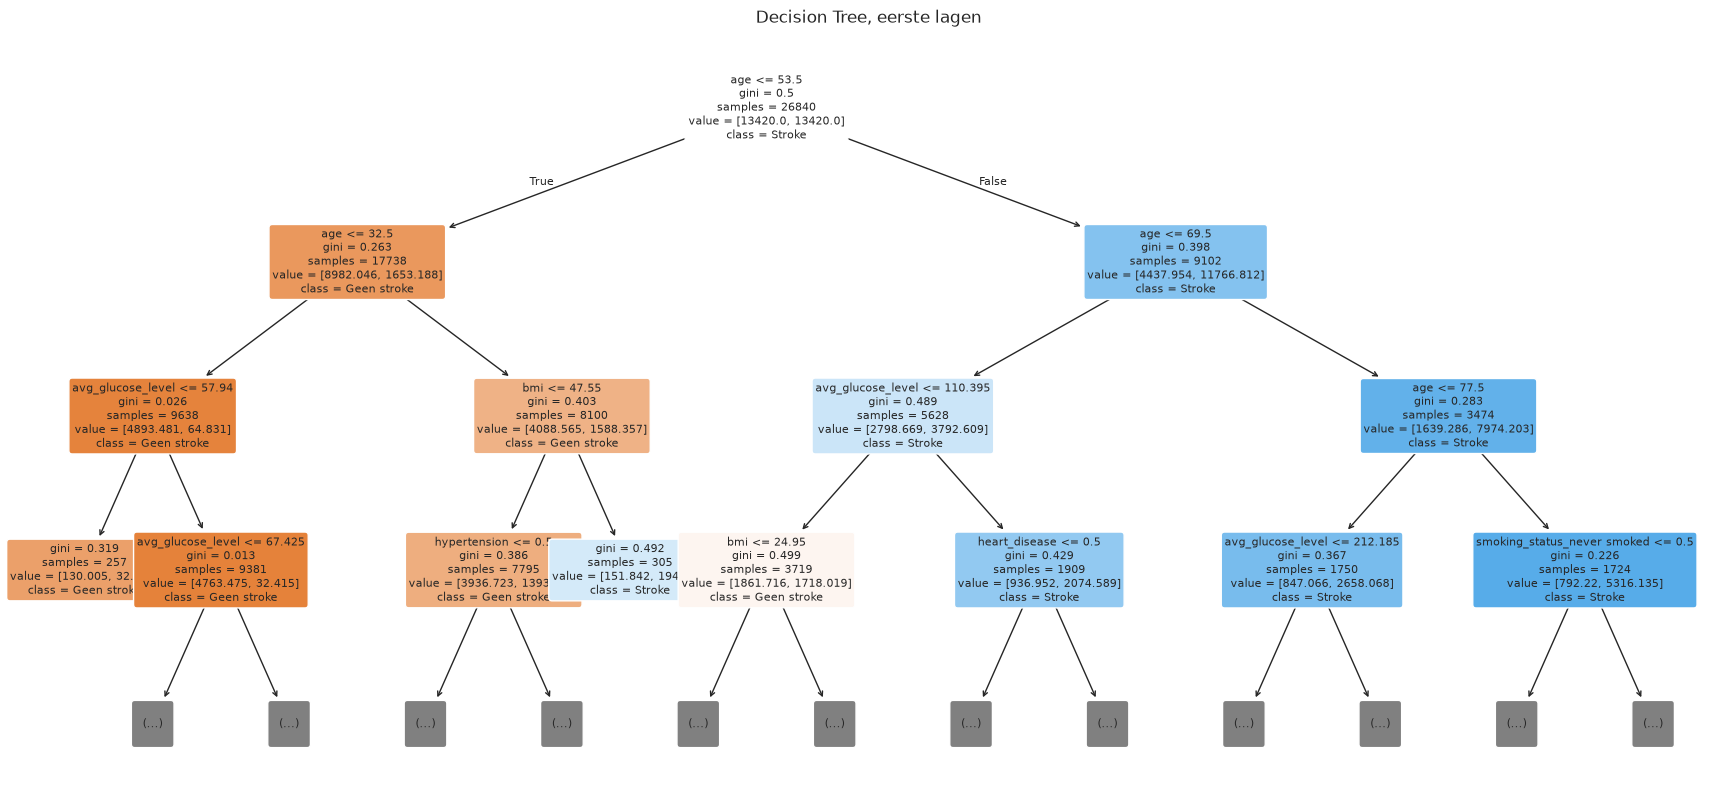

In [15]:
plt.figure(figsize=(22, 10))
plot_tree(
    best_tree,
    feature_names=list(X.columns),
    class_names=["Geen stroke", "Stroke"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8,
)
plt.title("Decision Tree, eerste lagen")
plt.show()


## 13. Scores opslaan

We slaan de belangrijkste scores op in `decision_tree_scores.csv`, zodat het Decision Tree-model makkelijk vergeleken kan worden met de modellen van groepsgenoten.


In [16]:
default_metrics = evaluate_threshold(y_valid, valid_proba, 0.5)
default_metrics["model"] = "Decision Tree"
default_metrics["setting"] = "threshold_0.5"

best_metrics = evaluate_threshold(y_valid, valid_proba, best_threshold)
best_metrics["model"] = "Decision Tree"
best_metrics["setting"] = "best_threshold"

scores_df = pd.DataFrame([default_metrics, best_metrics])
scores_df["best_cv_f1"] = grid_search.best_score_
scores_df["best_params"] = str(grid_search.best_params_)

scores_output_path = "decision_tree_scores.csv"
scores_df.to_csv(scores_output_path, index=False)

display(scores_df)
print("Scores opgeslagen als:", scores_output_path)


,threshold,f1,precision,recall,accuracy,roc_auc,pr_auc,tn,fp,fn,tp,model,setting,best_cv_f1,best_params
0,0.50,0.078368,0.041477,0.708738,0.744113,0.830077,0.053111,4920,1687,30,73,Decision Tree,threshold_0.5,0.089796,"{'ccp_alpha': 0.0, 'class_weight': 'balanced',..."
1,0.71,0.121780,0.069241,0.504854,0.888227,0.830077,0.053111,5908,699,51,52,Decision Tree,best_threshold,0.089796,"{'ccp_alpha': 0.0, 'class_weight': 'balanced',..."


Scores opgeslagen als: decision_tree_scores.csv


## 14. Kaggle-submission maken

Na tuning trainen we het beste Decision Tree-model opnieuw op de volledige trainingsdataset.  
Daarna maken we voorspellingen voor `test.csv`.

Het bestand krijgt dezelfde structuur als `sample_submission.csv`:
- `id`;
- `stroke`.


In [17]:
final_tree = DecisionTreeClassifier(
    random_state=RANDOM_STATE,
    **grid_search.best_params_,
)

final_tree.fit(X, y)

test_proba = final_tree.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)

submission_df = pd.DataFrame({
    "id": test_ids,
    "stroke": test_pred,
})

submission_output_path = "submission_decision_tree.csv"
submission_df.to_csv(submission_output_path, index=False)

display(submission_df.head())
print("Submission opgeslagen als:", submission_output_path)
print("\nVerdeling voorspellingen:")
print(submission_df["stroke"].value_counts(normalize=True).round(4))


,id,stroke
0,32840,0
1,45158,0
2,56105,0
3,3112,0
4,35224,0


Submission opgeslagen als: submission_decision_tree.csv

Verdeling voorspellingen:
stroke
0    0.8414
1    0.1586
Name: proportion, dtype: float64


## 15. Conclusie Decision Tree

Het Decision Tree-model is goed uitlegbaar, omdat het werkt met duidelijke beslisregels. Dat is een voordeel in een medische context, omdat zorgprofessionals beter kunnen begrijpen waarom een model een bepaalde voorspelling maakt.

De dataset is wel sterk imbalanced. Daarom is `class_weight="balanced"` gebruikt en is threshold tuning toegepast. Hierdoor probeert het model meer patiënten met `stroke = 1` te herkennen.

De beste instellingen zijn gevonden met cross-validation en hyperparameter tuning. De uiteindelijke beoordeling is gedaan met de F1-score, precision, recall, ROC-AUC, PR-AUC en een confusion matrix.

Een beperking van Decision Trees is dat ze gevoelig zijn voor overfitting. Daarom zijn pruning-gerelateerde hyperparameters gebruikt, zoals `max_depth`, `min_samples_leaf`, `min_samples_split` en `ccp_alpha`.

Voor een medisch advies zou ik dit model niet zelfstandig gebruiken, maar als ondersteunend model. De prestaties moeten altijd worden beoordeeld naast medische kennis en andere modellen uit het groepsnotebook.


## 16. Gebruik van Generatieve AI

Voor dit Decision Tree-onderdeel is ChatGPT gebruikt als hulpmiddel bij het structureren van het notebook, het schrijven van uitleg en het opzetten van voorbeeldcode.

Specifiek is GenAI gebruikt bij:
- het formuleren van uitleg over Decision Trees;
- het uitleggen van Gini impurity, entropy en pruning;
- het structureren van de code voor train/validatie-splitsing;
- het opzetten van cross-validation en hyperparameter tuning;
- het toepassen van threshold tuning;
- het maken van de confusion matrix;
- het formuleren van de conclusie.

De code en resultaten zijn gecontroleerd door de student. De modelresultaten komen voort uit het uitvoeren van de code op de aangeleverde dataset.

**Gebruikte prompt:**

> Ik werk aan een machine-learningopdracht waarin ik moet voorspellen of een patiënt een herseninfarct krijgt op basis van een stroke-dataset. Mijn taak binnen de groep is om het Decision Tree-model uit te werken. Kun je mij helpen met het opzetten van een Decision Tree-onderdeel in een Jupyter Notebook? Ik heb hulp nodig bij het uitleggen hoe een Decision Tree werkt, het uitleggen van Gini impurity, entropy, pruning, underfitting en overfitting, het toepassen van cross-validation en hyperparameter tuning, het omgaan met een imbalanced dataset, het evalueren met F1-score en confusion matrix, en het maken van voorspellingen voor een Kaggle-submissionbestand. Schrijf de uitleg in het Nederlands op studentniveau.


## 17. Bronnen

OpenAI. (2026). ChatGPT. Gebruikt als ondersteuning bij het maken, structureren en uitleggen van het Decision Tree-model voor de opdracht *Voorspel herseninfarct*. Geraadpleegd op 7 oktober 2026, van https://chat.openai.com/

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
